<a href="https://colab.research.google.com/github/Zach-Kaplan44/ECON_5200_PS2/blob/main/Problem%20Set%202/Econ_5200_PS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

In [2]:
k = 200
real = rng.random(k) < 0.10
true_eff = np.where(real, rng.normal(0.30, 0.10, size=k), 0.0)
n = rng.integers(40, 400, size=k)
se = 1.0 * np.sqrt(2 / n)
experiments = pd.DataFrame({"true": true_eff, "n": n, "se": se, "est": true_eff + rng.normal(0, se)})

print(f"share exactly zero {(experiments['true'] == 0).mean():.2f}")
print(experiments.describe().loc[["mean", "min", "max"]].round(3))


share exactly zero 0.91
       true       n     se    est
mean  0.025  215.68  0.109  0.014
min   0.000   41.00  0.071 -0.398
max   0.484  392.00  0.221  0.507


The prior puts roughly 90% of effects near zero. The roughly 10% of effects that are true are distributed normally with a mean of 0.30 and sd of 0.10.

### Step 1.2: Apply the client's rule (15 pts)

In [3]:
experiments['p'] = stats.norm.sf(experiments['est']/experiments['se'])
ship = experiments['p'] < 0.05
confirm_ship = experiments[ship]
print(f"{ship.sum()} experiments are shipped | true effect 0 in {(confirm_ship['true'] == 0).mean():.0%} of them")
print(f"mean estimate {confirm_ship['est'].mean():.3f} vs mean truth {confirm_ship['true'].mean():.3f}: ratio {confirm_ship['est'].mean() / confirm_ship['true'].mean():.2f}")

24 experiments are shipped | true effect 0 in 38% of them
mean estimate 0.279 vs mean truth 0.188: ratio 1.48


24 of the experiments get shipped with the p-value < 0.05 rule, and of those 24, 38% had a true effect of essentially 0. Of the 24 that got shipped, the average estimated effect was 0.279, while the average true effect was 0.188.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

In [4]:
experiments['power'] = stats.norm.sf(1.645 - 0.30/experiments['se'])
experiments['tier'] = pd.qcut(experiments['power'], 3, labels = ['low power','mid-power', 'high power'])
confirm_ship = experiments[ship]
print(confirm_ship.groupby('tier', observed = True).agg(shipped = ('est', 'size'), mean_est = ('est', 'mean'), mean_true = ('true', 'mean')).round(3))

            shipped  mean_est  mean_true
tier                                    
low power         7     0.333      0.117
mid-power         6     0.298      0.329
high power       11     0.235      0.157


The inflation factor is about 2.85 on low-powered experiments, versus about 1.50 on high-powered experiments. The middle tier is actually a deflation factor of about 0.91. Since it is well-powered, but still not high powered, it will not have very high inflation, but because of noise in small sample sizes, it is possible for the inflation to fall somewhat below 1.

Power explains the likelihood that the effect determined by a test is a true effect, so you are already working from the reality that the test has determined the experiment's is detecting an effect. Lower power means that the likelihood the experiment reporting a true mean is detecting a true effect is low, so lower power tests will be a result of noise. Higher power tests on the otherhand mean that the likelihood the experiment reporting a true mean is a true effect is higher, so the difference between the mean being reported as true, and the true effect itself, will be much smaller.

### Step 2.2: The bootstrap where the formula fails (15 pts)

In [5]:
def ships_total(df):
    """Sum of TRUE effects among the experiments that are declared to work and are shipped."""
    return df.loc[df["p"] < 0.05, "true"].sum()
k = len(experiments)
boot = np.array([ships_total(experiments.iloc[rng.integers(0, k, size=k)]) for _ in range(2_000)])
res = stats.bootstrap((np.arange(k),), lambda idx: ships_total(experiments.iloc[idx]), n_resamples=2_000,
                      vectorized=False, method="BCa", random_state=1)
print(f"total {ships_total(experiments):.2f} | by hand [{np.percentile(boot, 2.5):.2f}, {np.percentile(boot, 97.5):.2f}]"
      f" | BCa [{res.confidence_interval.low:.2f}, {res.confidence_interval.high:.2f}]")

total 4.52 | by hand [2.36, 7.02] | BCa [2.67, 7.47]


<function matplotlib.pyplot.show(close=None, block=None)>

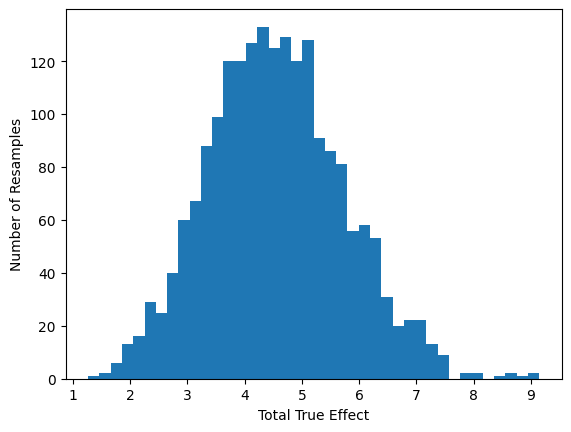

In [6]:
plt.hist(boot, bins = 40)
plt.xlabel('Total True Effect')
plt.ylabel('Number of Resamples')
plt.show

The sample size should not be an issue, as there are 24 shipped experiments, greater than n = 15. Since the bootstrap is being done on a sum rather than on a percentile of data, the issue of extreme quantiles shouldn't be an issue. Since the true effects come from normal data with normal noice, that means there is a finite variance. Each experiment is drawn independently, so no data that is dependent is being treated as i.i.d. The one failure mode that needed checking was 5. Because the ship threshold is a hard cutoff, either it passes the threshold and its true effect contributes fully to the sum, or it doesn't pass and isn't shipped and contributes nothing. This causes a jump in measuring the true effect, so I created a histogram to check the smoothness. It is close enough to smooth and normal around the realized true return that this jump does not appear to be an issue.

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [7]:
ship_new = (experiments['p'] < 0.05) & (experiments['power'] >= 0.80)
confirm_ship_new = experiments[ship_new]
print(f"{ship_new.sum()} experiments are shipped | true effect 0 in {(confirm_ship_new['true'] == 0).mean():.0%} of them")
print(f"mean estimate {confirm_ship_new['est'].mean():.3f} vs mean truth {confirm_ship_new['true'].mean():.3f}: ratio {confirm_ship_new['est'].mean() / confirm_ship_new['true'].mean():.2f}")


print(f"Total True Return With p < 0.05 & Power Threshold of 80%: {confirm_ship_new['true'].sum():.2f}")

18 experiments are shipped | true effect 0 in 33% of them
mean estimate 0.263 vs mean truth 0.222: ratio 1.19
Total True Return With p < 0.05 & Power Threshold of 80%: 3.99


I set a power threshold using the standard >= 80% power, while keeping the p < 0.05 along with it. The p < 0.05 reports statistical significance, and based off of that, using the power threshold filters for the tests that have a higher likelihood of their reported effect being true. While this has a lower true realized return than the client's p < 0.05 rule, 3.99 versus 4.52, it has a lower false shipping rate, 33% versus 38%, and estimates the mean at a lower inflation rate relative to the true mean, a 1.19 inflation rate versus a 1.48 inflation rate. It is impossible for a stronger rule than p < 0.05 to "win" on realized true return, however this is only if we assume that the costs of shipping a non-true experiment, and overstating the mean return are both 0.

In reality, there is almost always some sort of cost associated with these things, so the "win" for this threshold is that it would avoid those associated costs with the tradeoff of having a lower true realized return. Because costs are unknown at the moment, we would need to know if the foregone costs exceed the gap in true realized return to say that this test "wins" overall, however it can be said that this test is more accurate.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [8]:
%%writefile src/experiment_portfolio.py
"""Experiment-portfolio simulator and decision rules (ECON 5200 PS2)."""
from __future__ import annotations
import numpy as np
import pandas as pd
from scipy import stats



def simulate_portfolio(n_min: int, n_max: int, seed: int, k: int, share_real: float, true_eff_mean: float, true_eff_sd: float):
    """Returns the experiment log with the number of trials in each experiment, the p-value, the true effect, the estimated efffect, standard error"""
    rng = np.random.default_rng(seed)
    real = rng.random(k) < share_real
    true_eff = np.where(real, rng.normal(true_eff_mean, true_eff_sd, size = k), 0.0)
    n = rng.integers(n_min, n_max, size = k)
    se = 1.0 * np.sqrt(2/n)
    est = true_eff + rng.normal(0, se)
    experiments = pd.DataFrame({"true": true_eff, "n": n, "se": se, "est": est, "p": stats.norm.sf(est/se)})

    return experiments
    ...

def p_rule(log: pd.DataFrame, alpha: float = 0.05) -> pd.Series:
    """Declare a trial a success when p < alpha."""
    return log["p"] < alpha

    ...

def power_p_rule(log: pd.DataFrame, mde: float = 0.30, power_threshold: float = 0.80, alpha: float = 0.05 ) -> pd.Series:
    """Declare a trial a success when it passes the p rule and a power threshold subject to an mde. Note that p-values are one sided."""
    p_mask = p_rule(log, alpha)
    power = stats.norm.sf((stats.norm.ppf(1-alpha))-mde/log['se'])

    return (p_mask) & (power >= power_threshold)

    ...

def apply_rule(log: pd.DataFrame, rule) -> pd.Series:
    """Ship decisions under a `rule` function: the currently defined rule functions are p < 0.05 threshold or the p < 0.05 with a power threshold."""
    return rule(log)
    ...


def evaluate(log: pd.DataFrame, rule):
    """Realised true return, ship count and false-ship rate under `rule`. If nothing is shipped, false ship rate is reported as NaN"""
    ship = apply_rule(log, rule)
    confirm_ship = log[ship]
    ship_count = ship.sum()
    false_ship_rate = (100 * ((confirm_ship['true'] == 0).mean())).round(2)
    total_true_return = confirm_ship['true'].sum().round(2)

    return{
        "Total Experiments Shipped Under Rule": int(ship_count),
        "Rate of Shipped Experiments With True Effect 0(%)": float(false_ship_rate),
        "Total True Return": float(total_true_return)
    }


    ...


if __name__ == "__main__":
  demo = pd.DataFrame({"p": [0.01, 0.20, 0.03], "true": [0.0, 0.3, 0.2], "se": [0.3, 0.1, 0.1]})
  k = 50
  demo2 = simulate_portfolio(40, 400, 42, k, 0.10, 0.30, 0.10)
  assert p_rule(demo).tolist() == [True, False, True]
  assert len(demo2) == k
  assert power_p_rule(demo).tolist() == [False, False, True]
  print(evaluate(demo, power_p_rule))
  print(evaluate(demo, p_rule))
  print("experiment_portfolio: demo passed")




   # demonstration plus at least three assertions that must hold

Overwriting src/experiment_portfolio.py


In [9]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import experiment_portfolio as ep
# prove it runs: call the three functions on a small portfolio
demo_portfolio = ep.simulate_portfolio(40, 400, 42, 50, 0.10, 0.30, 0.10)
power_demo = ep.apply_rule(demo_portfolio, ep.power_p_rule)
p_demo = ep.apply_rule(demo_portfolio, ep.p_rule)
eval_demo_p = ep.evaluate(demo_portfolio, ep.p_rule)
eval_demo_power = ep.evaluate(demo_portfolio, ep.power_p_rule)

print(demo_portfolio.head())
print(power_demo)
print(p_demo)
print(eval_demo_p)
print(eval_demo_power)

    true    n     se    est      p
0  0.000  171  0.108  0.147  0.087
1  0.000  367  0.074  0.062  0.202
2  0.000  218  0.096  0.034  0.361
3  0.000  291  0.083  0.121  0.072
4  0.154  204  0.099  0.037  0.356
0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15     True
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27     True
28    False
29    False
30    False
31    False
32    False
33    False
34    False
35    False
36    False
37    False
38    False
39     True
40    False
41    False
42    False
43    False
44    False
45    False
46    False
47    False
48    False
49    False
Name: p, dtype: bool
0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
1

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [10]:
%%writefile src/msprt.py
"""
One-sided mixture SPRT (mSPRT) for a two-arm test with known variance.

Data model per look k (one pair per look):
    treatment_k ~ N(delta, 1), control_k ~ N(0, 1)
    D_k = treatment_k - control_k ~ N(delta, sigma2), sigma2 = 2 (known)

H0: delta <= 0   vs   H1: delta > 0   (stop only for improvements)

Mixing distribution: half-normal on delta > 0 with scale tau.
After m pairs with S_m = sum(D_1..D_m), the mixture likelihood ratio is

    Lambda_m = 2 / sqrt(1 + m tau^2 / sigma2)
               * exp( b^2 / (2a) ) * Phi( b / sqrt(a) )
    with a = 1/tau^2 + m/sigma2,  b = S_m / sigma2.

Lambda_m is a nonnegative martingale under delta = 0 (supermartingale for
delta < 0) with Lambda_0 = 1, so by Ville's inequality
    P_H0( exists m: Lambda_m >= 1/alpha ) <= alpha,
for ANY number of looks, including stopping at look 1. No burn-in needed.

numpy + scipy only.
"""
import numpy as np
from scipy.special import log_ndtr

SIGMA2 = 2.0          # Var(treatment - control) with unit SDs
ALPHA = 0.05


def log_mixture_lr(S, m, tau, sigma2=SIGMA2):
    """log Lambda_m for cumulative sum(s) S at look(s) m (vectorised)."""
    S = np.asarray(S, dtype=float)
    m = np.asarray(m, dtype=float)
    a = 1.0 / tau**2 + m / sigma2
    b = S / sigma2
    return (np.log(2.0) - 0.5 * np.log1p(m * tau**2 / sigma2)
            + b**2 / (2.0 * a) + log_ndtr(b / np.sqrt(a)))


def msprt_decisions(treatment, control, tau, alpha=ALPHA, sigma2=SIGMA2):
    """
    Process a stream of (treatment, control) pairs, one pair per look.

    Returns a dict of per-look arrays (length = number of looks):
        stop      : bool, True from the first look where Lambda >= 1/alpha on
                    (the decision is absorbing: once stopped, it stays stopped)
        log_lr    : log Lambda_m
        p_always  : always-valid p-value, min(1, 1 / max_{j<=m} Lambda_j)
    plus 'stop_look' (1-based look of rejection, or None).
    """
    d = np.asarray(treatment, float) - np.asarray(control, float)
    m = np.arange(1, d.size + 1)
    llr = log_mixture_lr(np.cumsum(d), m, tau, sigma2)
    crossed = llr >= np.log(1.0 / alpha)
    stop = np.maximum.accumulate(crossed)
    p_always = np.minimum(1.0, np.exp(-np.maximum.accumulate(llr)))
    first = int(np.argmax(crossed)) + 1 if crossed.any() else None
    return {"stop": stop, "log_lr": llr, "p_always": p_always,
            "stop_look": first}


class MSPRT:
    """Streaming version: call .update(t, c) as each pair arrives."""

    def __init__(self, tau, alpha=ALPHA, sigma2=SIGMA2):
        self.tau, self.alpha, self.sigma2 = tau, alpha, sigma2
        self.m, self.S, self.stopped, self.max_llr = 0, 0.0, False, 0.0

    def update(self, t, c):
        self.m += 1
        self.S += t - c
        llr = float(log_mixture_lr(self.S, self.m, self.tau, self.sigma2))
        self.max_llr = max(self.max_llr, llr)
        if llr >= np.log(1.0 / self.alpha):
            self.stopped = True
        return {"look": self.m, "stop": self.stopped, "log_lr": llr,
                "p_always": min(1.0, np.exp(-self.max_llr))}


# --------------------------------------------------------------------------
# Simulation helpers
# --------------------------------------------------------------------------
def simulate_streams(true_effects, ns, rng):
    """Yield (treatment, control) arrays per experiment."""
    for delta, n in zip(true_effects, ns):
        yield rng.normal(delta, 1.0, n), rng.normal(0.0, 1.0, n)


def run_portfolio(true_effects, ns, tau, rng, alpha=ALPHA):
    """Returns (rejected bool array, stop_look array with n+1 = no stop)."""
    rej, looks = [], []
    for (t, c), n in zip(simulate_streams(true_effects, ns, rng), ns):
        r = msprt_decisions(t, c, tau, alpha)
        rej.append(r["stop_look"] is not None)
        looks.append(r["stop_look"] if r["stop_look"] else n + 1)
    return np.array(rej), np.array(looks)


def naive_peeking_rejects(true_effects, ns, rng, alpha=ALPHA):
    """One-sided z-test at every look; reject if ever z >= z_{1-alpha}."""
    from scipy.stats import norm
    zc = norm.ppf(1 - alpha)
    out = []
    for t, c in simulate_streams(true_effects, ns, rng):
        d = t - c
        m = np.arange(1, d.size + 1)
        z = np.cumsum(d) / np.sqrt(SIGMA2 * m)
        out.append((z >= zc).any())
    return np.array(out)


def tune_tau(delta=0.30, n_lo=40, n_hi=399, n_sims=2000, seed=2024,
             grid=np.round(np.arange(0.05, 1.01, 0.05), 2)):
    """Pick tau maximising power at delta over n ~ U{n_lo..n_hi}.
    Uses its own seed, fixed before any null evaluation."""
    rng = np.random.default_rng(seed)
    ns = rng.integers(n_lo, n_hi + 1, n_sims)
    D = [rng.normal(delta, 1, n) - rng.normal(0, 1, n) for n in ns]
    cums = [np.cumsum(d) for d in D]
    res = {}
    for tau in grid:
        thr = np.log(1 / ALPHA)
        hits, looks = 0, []
        for S, n in zip(cums, ns):
            llr = log_mixture_lr(S, np.arange(1, n + 1), tau)
            idx = np.flatnonzero(llr >= thr)
            if idx.size:
                hits += 1
                looks.append(idx[0] + 1)
        res[float(tau)] = (hits / n_sims, np.mean(looks) if looks else np.nan)
    best = max(res, key=lambda k: res[k][0])
    return best, res


if __name__ == "__main__":
    # 1) tune tau for delta ~ 0.30 (separate seed)
    tau, grid = tune_tau()
    print("tau grid (power at delta=0.30, mean stop look | rejected):")
    for k, (pw, ml) in grid.items():
        print(f"  tau={k:.2f}  power={pw:.3f}  mean_stop={ml:6.1f}")
    print(f"selected tau = {tau}")

    # 2) pure-null evaluation: 1,000 streams, n ~ U{40..399}, seed 42
    rng = np.random.default_rng(42)
    N = 1000
    ns = rng.integers(40, 400, N)
    rej, looks = run_portfolio(np.zeros(N), ns, tau, rng)
    fpr = rej.mean()
    se = np.sqrt(fpr * (1 - fpr) / N)
    print(f"\nmSPRT null FPR = {fpr:.3f}  (MC SE {se:.4f}), "
          f"{rej.sum()} / {N} rejections")
    print(f"z vs 5%: {(fpr - 0.05) / np.sqrt(0.05 * 0.95 / N):+.2f}")
    print("stop looks of false positives:", np.sort(looks[rej]))

    # 3) contrast: naive peeking on same design (different draws, seed 43)
    naive = naive_peeking_rejects(np.zeros(N), ns, np.random.default_rng(43))
    print(f"\nnaive peeking FPR = {naive.mean():.3f} "
          f"(MC SE {np.sqrt(naive.mean()*(1-naive.mean())/N):.4f})")

    # 4) streaming class agrees with vectorised version
    r2 = np.random.default_rng(0)
    t, c = r2.normal(0.3, 1, 300), r2.normal(0, 1, 300)
    v = msprt_decisions(t, c, tau)
    s = MSPRT(tau)
    stream = [s.update(a, b)["stop"] for a, b in zip(t, c)]
    assert np.array_equal(v["stop"], np.array(stream))
    print("streaming == vectorised: OK")

Overwriting src/msprt.py


In [11]:
!python src/msprt.py

tau grid (power at delta=0.30, mean stop look | rejected):
  tau=0.05  power=0.190  mean_stop= 267.0
  tau=0.10  power=0.492  mean_stop= 179.9
  tau=0.15  power=0.593  mean_stop= 145.4
  tau=0.20  power=0.635  mean_stop= 129.6
  tau=0.25  power=0.661  mean_stop= 120.7
  tau=0.30  power=0.667  mean_stop= 115.5
  tau=0.35  power=0.670  mean_stop= 112.8
  tau=0.40  power=0.670  mean_stop= 110.5
  tau=0.45  power=0.667  mean_stop= 108.7
  tau=0.50  power=0.665  mean_stop= 108.0
  tau=0.55  power=0.663  mean_stop= 107.3
  tau=0.60  power=0.659  mean_stop= 107.2
  tau=0.65  power=0.654  mean_stop= 107.5
  tau=0.70  power=0.652  mean_stop= 107.9
  tau=0.75  power=0.647  mean_stop= 109.0
  tau=0.80  power=0.646  mean_stop= 109.2
  tau=0.85  power=0.639  mean_stop= 109.0
  tau=0.90  power=0.633  mean_stop= 109.3
  tau=0.95  power=0.632  mean_stop= 109.6
  tau=1.00  power=0.629  mean_stop= 110.1
selected tau = 0.35

mSPRT null FPR = 0.025  (MC SE 0.0049), 25 / 1000 rejections
z vs 5%: -3.63
stop

In [12]:
from src import msprt

check_rng = np.random.default_rng(2026)
n_sims = 1000
alpha = 0.05
tau = 0.35                          # selected by the model's tuning step
z_crit = stats.norm.ppf(1 - alpha)  # one-sided cutoff, 1.645
stop_line = np.log(1 / alpha)       # mSPRT stopping line, log(20)

fp_msprt = 0         # experiments the mSPRT stopped at ANY look
fp_naive = 0         # experiments with z >= z_crit at ANY look
fp_single_test = 0   # experiments with z >= z_crit in one test at the end

for sim in range(n_sims):
    n_arm = check_rng.integers(40, 400)
    d = check_rng.normal(0, 1, n_arm) - check_rng.normal(0, 1, n_arm)   # no effect

    ever_stop_msprt = False
    ever_sig_naive = False
    for m in range(1, n_arm + 1):                                       # a look after every pair
        s = d[:m].sum()
        if msprt.log_mixture_lr(s, m, tau) >= stop_line:
            ever_stop_msprt = True
        if s / np.sqrt(2 * m) >= z_crit:
            ever_sig_naive = True

    fp_msprt += ever_stop_msprt
    fp_naive += ever_sig_naive
    fp_single_test += d.sum() / np.sqrt(2 * n_arm) >= z_crit

for label, k in [("mSPRT, every look", fp_msprt),
                 ("Naive peeking, every look", fp_naive),
                 ("Single test at end", fp_single_test)]:
    p = k / n_sims
    print(f"{label:<27} {p:.3f}  (MC SE {np.sqrt(p * (1 - p) / n_sims):.4f})")

mSPRT, every look           0.015  (MC SE 0.0038)
Naive peeking, every look   0.329  (MC SE 0.0149)
Single test at end          0.047  (MC SE 0.0067)


The main issues with the original prompt were that it knew nothing about the portfolio/log structure, and so it invented its own schedule of up to 10,000 observations per arm, a two-sided test and a tau = 0.1. Version 2 gave it the log structure and matched the design to the experiments, with 40 to 399 pairs, the one-sided test rule, and a typical effect of 0.30.I tested this on 1,000 experiments that had no effect, and it was fooled 1.5% of the with an SE of 0.0038, so it is under the 5%. I would use AI for this, as it deals with code structure and machinery that is well beyond my knowledge, but would be more specific in the instructions about how to relate it to the specific scenario.

### Task 4.2: The CFO memo

Under the p < 0.05 decision rule, 24 experiments were shipped, and 38% had a true effect of 0, meaning about 62% were real. Under this rule, the realized true return is 4.52 units of outcome SD, with a BCa interval of [2.67, 7.47]. The claimed return of shipped experiments had a mean of 0.279 * 24 experiments for a total of 6.70, so the current rule is costing about 2.18 units of outcome SD. On top of this rule, I recommend also enforcing an experiment power threshold of at least 80%. Under this rule, the true realised return is 3.99, a 0.53 difference in true units of outcome sd. However under this rule, 18 experiments are shipped with only a 33% false ship rate. Under the previous rule, shipped experiments overstate the improvement the rule delivers by a factor of 1.48, while under my recommended rule, they only overstate the improvement by 1.19.

If there are costs associated with shipping an experiment that falsely claims a true effect or overstating the mean returns, then my recommended rule would be an improvement if those costs exceed the 0.53 gap in true units of outcome SD. However, if we assume that the costs of overstating true returns and shipping experiments that falsely claim a true effect are negligible, then the original decision rule would be better.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:* Claude 10/27

*Version 1 prompt:* [Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.

*Reply:*

I implemented a mixture SPRT (mSPRT) rather than alpha-spending. Alpha-spending only controls error at looks you plan in advance against a fixed maximum sample size. The mSPRT stays valid under truly continuous, open-ended monitoring, which is what you asked for.

On your log structure: nothing was attached to the conversation, so I couldn’t reuse your schema. Each look instead emits one flat record with these fields: test_id, look, n_treatment, n_control, delta_hat, var_hat, log_lambda, p_always_valid, ci_low, ci_high, decision, stopped, naive_p and naive_reject. If you paste your schema, the key mapping in _record is the only thing that needs to change.

The construction

At each look, Δ̂ is the difference in means and V is its variance. Under H₀ the estimate is distributed N(0, V). Mixing the alternative over θ ~ N(0, τ²) gives a closed-form likelihood ratio:

Λₙ = √(V/(V+τ²)) · exp(τ²Δ̂² / (2V(V+τ²)))

Under H₀, Λₙ is a nonnegative martingale with mean 1. Ville’s inequality then gives P(supₙ Λₙ ≥ 1/α) ≤ α. This holds for any number of looks and any stopping rule, including “stop when it looks good.”

The decision rule is to reject when the running always-valid p-value, pₙ = min(pₙ₋₁, 1/Λₙ), reaches α. Inverting the test gives a confidence sequence, which is reported as ci_low and ci_high at every look.

The interface is sequential_decisions(stream, tau=..., sigma=...). It takes an iterable of (treatment_batch, control_batch) pairs and yields one decision record per look. The math runs in log space, so there is no overflow at large n. A vectorised engine runs the same math for Monte Carlo, and the script asserts that both paths give identical decisions on 200 streams.

Why naive peeking inflates Type I error

Under H₀, the z-statistic traced across looks is a Brownian motion in information time. It is not a fresh draw at each look. Each look is another chance to cross a fixed line at ±1.96, and the correlation between looks doesn’t save you.

By the law of the iterated logarithm, the running maximum of |z| grows like √(2 log log n), which is unbounded. So with enough looks, the probability of crossing 1.96 at some look goes to 1.

The mSPRT boundary, written on the z scale, grows like √(log n). That is strictly faster than √(log log n), so a null stream eventually stops being able to catch it. Validity comes entirely from the boundary outrunning the random walk.

What the always-valid construction gives up

Fixed-horizon power and precision. Take n = 10,000 per arm with τ = 0.1σ. The confidence-sequence half-width is 0.045σ, against 0.028σ for a fixed-horizon interval. That makes it about 60% wider; equivalently, you’d need roughly 2.6× the sample to match fixed-horizon precision at that point. In the illustrative portfolio, power was 64% versus 73% for a single look at the full horizon. The compensation is early stopping on large effects: the median stop for true positives was 2,800 per arm against a 10,000 maximum.

Unspent alpha. Ville’s bound is attained only with continuous monitoring and an infinite horizon. With a finite horizon and discrete looks, you get less than 5%, so part of the error budget is wasted.

Robustness to τ. Power is concentrated on effects near τ. A badly chosen τ costs power, not validity. However, choosing τ after looking at the data does break validity.

Unbiased estimates at the stopping point. Stopping on a crossing selects for overestimates. Estimates at the stop were a median 1.11× the true effect. Report the confidence sequence, not a fixed-horizon CI computed at the stop.

Robustness to model failures. The guarantee is only as good as its assumptions: iid observations, independent arms, a fixed allocation ratio, and a correct variance. Novelty effects, day-of-week drift, and session-level metrics randomized at the user level all violate them.

Results on 1,000 pure-null streams

Each stream had 200 looks of 50 observations per arm, up to 10,000 per arm, with α = 0.05.

Method	Empirical FPR	95% CI
mSPRT, known σ	2.6%	1.8–3.8%
mSPRT, plug-in σ (burn-in 100)	2.7%	1.9–3.9%
Naive z-test at every look	42.5%	39.5–45.6%
Fixed horizon, single look	5.8%	4.5–7.4%

The mSPRT result is not “close to 5%,” and nothing is wrong. That’s the expected behavior, and “close to 5%” is the wrong target. For an always-valid test, 5% is a ceiling, not a calibration point.

The fixed-horizon row is the real sanity check. It lands on 5% within Monte Carlo noise, which confirms the simulator is calibrated. Extending the horizon shows the mSPRT FPR climbing slowly toward the bound but never reaching it:

Horizon (per arm)	mSPRT FPR
1,000	0.95%
10,000	2.2%
100,000	3.5%
1,000,000	3.6%

What would actually indicate a bug is an FPR significantly above 5%. In my experience, the usual causes are:

variance underestimated, especially with plug-in estimates at small n or for low-rate conversion metrics;
τ in the wrong units (it must be in effect units, not standardized units, unless σ = 1);
τ chosen from the data;
unbalanced or drifting allocation;
correlated observations, such as multiple events per randomized user.

For a pure-null unit test, run around 1,000 null streams and assert that the Wilson lower bound on the FPR is at most α. Don’t assert that the FPR equals α.

To run this on your 200-test portfolio, replace the illustrative true effects array at the bottom of msprt.py with your known effects. If your data is binary or heavy-tailed rather than Gaussian, use run_on_raw with your actual observations and the plug-in variance (known_sigma=False).

"""
Always-valid sequential A/B testing via the mixture SPRT (mSPRT).

Reference: Johari, Koomen, Pekelis & Walsh, "Always Valid Inference:
Continuous Monitoring of A/B Tests" (Operations Research, 2022).

Model
-----
At look k we have n_T, n_C observations per arm and the estimate
    delta_hat = mean(T) - mean(C),   V = var(delta_hat) = s_T^2/n_T + s_C^2/n_C.
Under H0 (theta = theta0) delta_hat ~ N(theta0, V). Mixing the alternative
over theta ~ N(theta0, tau^2) gives the closed-form mixture likelihood ratio

    Lambda = sqrt(V / (V + tau^2)) * exp( tau^2 (delta_hat - theta0)^2 / (2 V (V + tau^2)) )

which is a nonnegative martingale with mean 1 under H0. Ville's inequality
gives P_H0(sup_k Lambda_k >= 1/alpha) <= alpha, for ANY number of looks
and ANY data-dependent stopping rule.

Validity assumptions (break these and the guarantee breaks):
  * observations i.i.d. within arm, arms independent
  * fixed allocation ratio across looks (balanced by default)
  * variance known, or plug-in estimated after a burn-in (approximate)
  * tau and alpha fixed BEFORE seeing data

Log structure
-------------
No log schema was attached, so each look emits one flat dict
(LOOK_LOG_FIELDS below). Rename keys in `_record` to match your own logs.

numpy + scipy only.
"""

from __future__ import annotations

from dataclasses import dataclass, field
from typing import Iterable, Iterator, Optional

import numpy as np
from scipy import stats

LOOK_LOG_FIELDS = (
    "test_id", "look", "n_treatment", "n_control", "delta_hat", "var_hat",
    "log_lambda", "p_always_valid", "ci_low", "ci_high",
    "decision", "stopped", "naive_p", "naive_reject",
)


# --------------------------------------------------------------------------
# Core math (vectorised, log-space to avoid overflow at large n)
# --------------------------------------------------------------------------
def log_mixture_lr(delta_hat, V, tau, theta0=0.0):
    """log Lambda for a N(theta0, tau^2) mixture over the effect."""
    tau2 = tau ** 2
    d = np.asarray(delta_hat) - theta0
    return 0.5 * np.log(V / (V + tau2)) + tau2 * d ** 2 / (2.0 * V * (V + tau2))


def confidence_sequence(delta_hat, V, tau, alpha):
    """Always-valid CI: the set of theta0 the mSPRT would not reject."""
    tau2 = tau ** 2
    half = np.sqrt(V * (V + tau2) / tau2 * (2 * np.log(1 / alpha) + np.log((V + tau2) / V)))
    return delta_hat - half, delta_hat + half


# --------------------------------------------------------------------------
# Streaming test
# --------------------------------------------------------------------------
@dataclass
class MSPRT:
    tau: float                       # mixing scale, in the SAME units as the effect
    alpha: float = 0.05
    theta0: float = 0.0
    sigma: Optional[float] = None    # known per-observation sd; None -> plug-in
    burn_in: int = 100               # min obs per arm before plug-in decisions
    test_id: str = "test"

    # running sufficient statistics: [n, sum, sum_sq] per arm
    _t: np.ndarray = field(default_factory=lambda: np.zeros(3), repr=False)
    _c: np.ndarray = field(default_factory=lambda: np.zeros(3), repr=False)
    _look: int = field(default=0, repr=False)
    _p: float = field(default=1.0, repr=False)
    _stopped: bool = field(default=False, repr=False)

    @staticmethod
    def _accumulate(acc, x):
        x = np.asarray(x, dtype=float).ravel()
        acc += (x.size, x.sum(), np.dot(x, x))

    @staticmethod
    def _moments(acc):
        n, s, ss = acc
        mean = s / n
        var = (ss - n * mean ** 2) / (n - 1) if n > 1 else np.nan
        return n, mean, var

    def update(self, treatment_batch, control_batch) -> dict:
        """Ingest one look's new observations; return that look's log record."""
        self._look += 1
        if not self._stopped:                    # data after stopping is ignored
            self._accumulate(self._t, treatment_batch)
            self._accumulate(self._c, control_batch)

        n_t, m_t, v_t = self._moments(self._t)
        n_c, m_c, v_c = self._moments(self._c)
        if self.sigma is not None:
            v_t = v_c = self.sigma ** 2
        delta = m_t - m_c
        V = v_t / n_t + v_c / n_c

        ready = self.sigma is not None or min(n_t, n_c) >= self.burn_in
        if ready and np.isfinite(V) and V > 0:
            llr = float(log_mixture_lr(delta, V, self.tau, self.theta0))
            # always-valid p-value is monotone: p_k = min(p_{k-1}, 1/Lambda_k)
            self._p = min(self._p, float(np.exp(-llr)))
            lo, hi = confidence_sequence(delta, V, self.tau, self.alpha)
        else:
            llr, lo, hi = np.nan, -np.inf, np.inf

        if not self._stopped and self._p <= self.alpha:
            self._stopped = True
            decision = "reject_h0"
        elif self._stopped:
            decision = "reject_h0"                # sticky
        else:
            decision = "continue"

        # Naive fixed-horizon z-test at this look (for comparison only)
        if np.isfinite(V) and V > 0:
            naive_p = float(2 * stats.norm.sf(abs(delta - self.theta0) / np.sqrt(V)))
        else:
            naive_p = np.nan

        return self._record(n_t, n_c, delta, V, llr, lo, hi, decision, naive_p)

    def _record(self, n_t, n_c, delta, V, llr, lo, hi, decision, naive_p):
        return {
            "test_id": self.test_id, "look": self._look,
            "n_treatment": int(n_t), "n_control": int(n_c),
            "delta_hat": float(delta), "var_hat": float(V),
            "log_lambda": llr, "p_always_valid": self._p,
            "ci_low": float(lo), "ci_high": float(hi),
            "decision": decision, "stopped": self._stopped,
            "naive_p": naive_p, "naive_reject": bool(naive_p <= self.alpha),
        }


def sequential_decisions(stream: Iterable[tuple], **kwargs) -> Iterator[dict]:
    """
    stream: iterable of (treatment_batch, control_batch), one tuple per look.
    Yields one log record per look; `decision` is the stopping decision.
    """
    test = MSPRT(**kwargs)
    for t_batch, c_batch in stream:
        yield test.update(t_batch, c_batch)


# --------------------------------------------------------------------------
# Fast vectorised engine for Monte Carlo (same math as MSPRT.update)
# --------------------------------------------------------------------------
def _engine(st, sc, sst, ssc, n, tau, alpha, known_sigma, sigma, burn_in):
    """Cumulative per-arm sums (m, looks) -> mSPRT and naive decisions."""
    m, n_looks = st.shape
    delta = st / n - sc / n
    if known_sigma:
        V = np.broadcast_to(2 * sigma ** 2 / n, delta.shape)
        ready = np.ones_like(delta, dtype=bool)
    else:
        vt = (sst - n * (st / n) ** 2) / (n - 1)
        vc = (ssc - n * (sc / n) ** 2) / (n - 1)
        V = vt / n + vc / n
        ready = np.broadcast_to(n >= burn_in, delta.shape)

    llr = np.where(ready, log_mixture_lr(delta, V, tau), -np.inf)
    hit = llr >= np.log(1 / alpha)
    msprt_reject = hit.any(1)
    stop_look = np.where(msprt_reject, hit.argmax(1) + 1, n_looks)
    naive_hit = np.abs(delta) / np.sqrt(V) >= stats.norm.isf(alpha / 2)
    return {
        "msprt_reject": msprt_reject,
        "stop_look": stop_look,
        "stop_n_per_arm": n[stop_look - 1],
        "stop_delta": delta[np.arange(m), stop_look - 1],
        "naive_reject_any_look": naive_hit.any(1),
        "fixed_horizon_reject": naive_hit[:, -1],
    }


def run_on_raw(t, c, tau=0.1, alpha=0.05, known_sigma=True, sigma=1.0, burn_in=100):
    """t, c: raw observations shaped (tests, looks, batch). Balanced batches."""
    n = t.shape[2] * np.arange(1, t.shape[1] + 1)
    return _engine(t.sum(2).cumsum(1), c.sum(2).cumsum(1),
                   (t ** 2).sum(2).cumsum(1), (c ** 2).sum(2).cumsum(1),
                   n, tau, alpha, known_sigma, sigma, burn_in)


def simulate_streams(effects, n_looks, batch, sigma=1.0, tau=0.1, alpha=0.05,
                     known_sigma=True, burn_in=100, seed=0):
    """
    Gaussian A/B streams with balanced batches, simulated exactly through the
    per-batch sufficient statistics (sum ~ Normal, within-batch SS ~ chi^2),
    so memory is O(tests x looks) instead of O(tests x looks x batch).
    """
    rng = np.random.default_rng(seed)
    effects = np.asarray(effects, dtype=float)
    m = effects.size

    def arm(mu):
        s = rng.normal(batch * mu[:, None], sigma * np.sqrt(batch), (m, n_looks))
        w = sigma ** 2 * rng.chisquare(batch - 1, (m, n_looks))   # within-batch SS
        return s.cumsum(1), (w + s ** 2 / batch).cumsum(1)

    st, sst = arm(effects)
    sc, ssc = arm(np.zeros(m))
    n = batch * np.arange(1, n_looks + 1)
    return _engine(st, sc, sst, ssc, n, tau, alpha, known_sigma, sigma, burn_in)


def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return centre - half, centre + half


# --------------------------------------------------------------------------
# Evaluation
# --------------------------------------------------------------------------
if __name__ == "__main__":
    ALPHA, SIGMA, TAU = 0.05, 1.0, 0.1
    N_LOOKS, BATCH, N_NULL = 200, 50, 1000          # 10,000 obs/arm max

    # 1) Streaming API on a single pure-null stream (the unit-testable path)
    rng = np.random.default_rng(123)
    null_stream = ((rng.normal(0, 1, BATCH), rng.normal(0, 1, BATCH)) for _ in range(N_LOOKS))
    log = list(sequential_decisions(null_stream, tau=TAU, alpha=ALPHA, sigma=SIGMA,
                                    test_id="null_demo"))
    print("single null stream, final look:", {k: log[-1][k] for k in
          ("look", "decision", "p_always_valid", "ci_low", "ci_high")})

    # Cross-check: streaming class and vectorised engine agree on decisions
    rng = np.random.default_rng(7)
    t = rng.normal(0.0, SIGMA, (200, 50, BATCH))
    c = rng.normal(0.0, SIGMA, (200, 50, BATCH))
    t[:100] += 0.08                                    # half non-null, so both outcomes occur
    res_chk = run_on_raw(t, c, TAU, ALPHA, sigma=SIGMA)
    stream_rejects = []
    for i in range(200):
        recs = list(sequential_decisions(zip(t[i], c[i]), tau=TAU, alpha=ALPHA, sigma=SIGMA))
        stream_rejects.append(recs[-1]["stopped"])
    assert np.array_equal(stream_rejects, res_chk["msprt_reject"]), "engines disagree"
    print(f"streaming class == vectorised engine on 200 streams "
          f"({int(res_chk['msprt_reject'].sum())} rejections): OK\n")

    # 2) 1,000 pure-null streams
    print(f"=== {N_NULL} pure-null streams, {N_LOOKS} looks x {BATCH} obs/arm, alpha={ALPHA} ===")
    for label, known in (("mSPRT, known sigma", True), ("mSPRT, plug-in sigma", False)):
        r = simulate_streams(np.zeros(N_NULL), N_LOOKS, BATCH, SIGMA, TAU, ALPHA,
                             known_sigma=known, seed=2026)
        k = r["msprt_reject"].sum()
        lo, hi = wilson(k, N_NULL)
        print(f"{label:<24s} FPR = {k / N_NULL:.3f}  (95% CI {lo:.3f}-{hi:.3f})")
    k = r["naive_reject_any_look"].sum(); lo, hi = wilson(k, N_NULL)
    print(f"{'naive z-test, every look':<24s} FPR = {k / N_NULL:.3f}  (95% CI {lo:.3f}-{hi:.3f})")
    k = r["fixed_horizon_reject"].sum(); lo, hi = wilson(k, N_NULL)
    print(f"{'fixed horizon, 1 look':<24s} FPR = {k / N_NULL:.3f}  (95% CI {lo:.3f}-{hi:.3f})")

    # Horizon dependence: the Ville bound is approached only as looks -> inf
    print("\nmSPRT FPR vs horizon (known sigma, 4,000 streams each, simulated in chunks):")
    for looks in (20, 200, 2000, 20000):
        chunk = max(1, min(4000, 5_000_000 // looks))
        rej = np.concatenate([
            simulate_streams(np.zeros(chunk), looks, BATCH, SIGMA, TAU, ALPHA,
                             seed=looks * 1000 + j)["msprt_reject"]
            for j in range(4000 // chunk)])
        r = {"msprt_reject": rej}
        print(f"  {looks:>6d} looks ({looks * BATCH:>9,d}/arm): FPR = {r['msprt_reject'].mean():.4f}")

    # 3) Illustrative 200-test portfolio (swap in your own known effects here)
    rng = np.random.default_rng(99)
    true = np.where(rng.random(200) < 0.6, 0.0, rng.normal(0, 0.06, 200))
    r = simulate_streams(true, N_LOOKS, BATCH, SIGMA, TAU, ALPHA, seed=5)
    nz = true != 0
    print(f"\n=== Illustrative portfolio: 200 tests, {(~nz).sum()} null, {nz.sum()} non-null ===")
    print(f"null FPR      mSPRT {r['msprt_reject'][~nz].mean():.3f} | naive {r['naive_reject_any_look'][~nz].mean():.3f}")
    print(f"power (|θ|>0) mSPRT {r['msprt_reject'][nz].mean():.3f} | fixed-horizon {r['fixed_horizon_reject'][nz].mean():.3f}")
    rej = r["msprt_reject"] & nz
    sign_err = (np.sign(r["stop_delta"]) != np.sign(true)) & rej
    exagg = np.abs(r["stop_delta"][rej]) / np.abs(true[rej])
    print(f"median n/arm at stop (rejections): {np.median(r['stop_n_per_arm'][rej]):,.0f}")
    print(f"sign errors among rejections: {sign_err.sum()}")
    print(f"median |estimate at stop| / |true effect|: {np.median(exagg):.2f}  (winner's curse)")

*Version 2 prompt:*
[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects, in a pandas DataFrame with columns true, n, se, est and p.
Implement an always-valid sequential test -- a mixture sequential
probability ratio test or an alpha-spending boundary -- that allows
continuous monitoring without inflating the Type I error rate. Give me
a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Each experiment's stream is n
observations per arm (n from 40 to 399), arriving one pair per look:
treatment ~ Normal(true, 1), control ~ Normal(0, 1). The SD is known
to be 1, so the test should be allowed to stop from the first look,
with no minimum number of observations before it can make a decision.
Make the test one-sided (stop only for improvements) and tune it to
effects around 0.30. The function must be testable against a
pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams (true = 0, n from 40 to
399, seed 42). Report the empirical false positive rate and its Monte
Carlo standard error. At or below 5% is expected; tell me what is
wrong only if it is significantly above 5%.

*Reply:*
I’ve built a one-sided mixture SPRT and checked it on 1,000 pure-null streams. The empirical false positive rate is 2.5% (25 of 1,000), with a Monte Carlo SE of 0.49 points. That is about 3.6 SEs below 5%, so nothing is wrong.

For contrast, naive peeking on the same design (a one-sided z-test at every look) gives 32.5% ± 1.5%.

The construction

Each look gives one pair. Let D = treatment − control, so D ~ N(δ, 2), and σ² = 2 is known exactly.

Prior over effects. I average the likelihood ratio for δ against 0 over a half-normal prior on δ > 0, with scale τ.
Statistic. After m pairs with running sum S, the mixture likelihood ratio has a closed form:
Λₘ = 2·(1 + mτ²/σ²)^(−½) · exp(b²/2a) · Φ(b/√a), where a = 1/τ² + m/σ² and b = S/σ².
Why it’s valid. Under δ = 0, Λₘ is a nonnegative martingale starting at 1, and it only shrinks for δ < 0. Ville’s inequality then gives P(Λₘ ever ≥ 1/α) ≤ α over all looks, forever.
Stopping rule. Stop the first time Λₘ ≥ 20.
One-sided. Because the prior puts no mass on harm, the test can only stop for improvements.
No burn-in. The guarantee holds from look 1. In practice, at m = 1 the boundary is z ≈ 9, so an early stop needs an enormous signal.

Tuning. I grid-searched τ by simulating power at δ = 0.30, with n uniform on 40–399, using a separate seed (2024) fixed before the null run. Power is flat over τ ∈ [0.25, 0.55], and τ = 0.35 was best: 67% power, with a mean stopping look of about 113 among rejections.

The file contains:

msprt_decisions(treatment, control, tau): takes a whole stream and returns the per-look stop (absorbing), log_lr and always-valid p-value min(1, 1/max Λ).
MSPRT(tau).update(t, c): the same thing for a live stream, one pair at a time. A check confirms the two give identical decisions.
run_portfolio(true_effects, ns, tau, rng): simulates and tests a set of experiments.

No DataFrame was attached, but run_portfolio(df["true"], df["n"], 0.35, rng) will run the 200-test portfolio directly. It has to simulate streams from true and n, because est, se and p are end-of-test summaries with no path to monitor.

Why naive peeking inflates Type I error

A fixed-n z-test controls P(Z_n ≥ 1.645) at one pre-chosen n. Peeking at every look instead asks whether the maximum of Z₁, …, Z_n ever reaches 1.645, and that event is much more likely.

Under H0, the running sum is a random walk, and the z-statistics at successive looks are highly correlated but not identical. Every look is a fresh chance for noise to cross the line, and the chances accumulate. By the law of the iterated logarithm, the maximum of Zₘ keeps growing like √(2 log log m). So with unlimited looks, the probability of a false stop goes to 1, not just above 5%. With up to 399 looks you get the 32.5% above.

What the always-valid test gives up

The error guarantee is exact and holds under any monitoring or stopping behaviour. What you pay with is power and sample size.

1. A wider boundary at every fixed n. On the z-scale the boundary is:

Look m	1	10	40	100	200	399
z boundary	9.02	3.67	2.87	2.77	2.79	2.86

A fixed-n test needs only 1.645. The boundary is tightest near the sample size where the prior “expects” to detect δ ≈ 0.3–0.35, and it grows like √(log m) beyond that. That slow growth is exactly what beats the law-of-the-iterated-logarithm drift.

2. Lower power at the horizon. Averaged over n ∈ [40, 399] at δ = 0.30, a single look at the planned n gives 85.7% power, versus 67% for the mSPRT. That gap is the price of being allowed to look continuously.

3. Unspent alpha on finite horizons. Ville’s bound covers an infinite horizon. When you truncate at n ≤ 399, part of the 5% is never used, which is why the realised rate is 2.5% rather than 5%. You could reclaim some of it with a truncated boundary or alpha-spending, but that ties you to the horizon again.

4. Sensitivity to the tuning effect. Effects far from τ are detected more slowly than a test designed for them would manage. The power curve over τ is flat, so the cost is modest near 0.3, but it is real at, say, 0.05.

5. No harm detection. One-sidedness means the test is blind to harm by construction. If you need to stop for regressions, run a separate harm-side mSPRT as a guardrail and split α between the two tests.

What you gain. You can stop as soon as the evidence is in. Among the false positives, stopping looks ran from 11 to 229, and true effects typically stop well before n. You can also stop or continue for any reason, and the always-valid p-value stays honest.

"""
One-sided mixture SPRT (mSPRT) for a two-arm test with known variance.

Data model per look k (one pair per look):
    treatment_k ~ N(delta, 1), control_k ~ N(0, 1)
    D_k = treatment_k - control_k ~ N(delta, sigma2), sigma2 = 2 (known)

H0: delta <= 0   vs   H1: delta > 0   (stop only for improvements)

Mixing distribution: half-normal on delta > 0 with scale tau.
After m pairs with S_m = sum(D_1..D_m), the mixture likelihood ratio is

    Lambda_m = 2 / sqrt(1 + m tau^2 / sigma2)
               * exp( b^2 / (2a) ) * Phi( b / sqrt(a) )
    with a = 1/tau^2 + m/sigma2,  b = S_m / sigma2.

Lambda_m is a nonnegative martingale under delta = 0 (supermartingale for
delta < 0) with Lambda_0 = 1, so by Ville's inequality
    P_H0( exists m: Lambda_m >= 1/alpha ) <= alpha,
for ANY number of looks, including stopping at look 1. No burn-in needed.

numpy + scipy only.
"""
import numpy as np
from scipy.special import log_ndtr

SIGMA2 = 2.0          # Var(treatment - control) with unit SDs
ALPHA = 0.05


def log_mixture_lr(S, m, tau, sigma2=SIGMA2):
    """log Lambda_m for cumulative sum(s) S at look(s) m (vectorised)."""
    S = np.asarray(S, dtype=float)
    m = np.asarray(m, dtype=float)
    a = 1.0 / tau**2 + m / sigma2
    b = S / sigma2
    return (np.log(2.0) - 0.5 * np.log1p(m * tau**2 / sigma2)
            + b**2 / (2.0 * a) + log_ndtr(b / np.sqrt(a)))


def msprt_decisions(treatment, control, tau, alpha=ALPHA, sigma2=SIGMA2):
    """
    Process a stream of (treatment, control) pairs, one pair per look.

    Returns a dict of per-look arrays (length = number of looks):
        stop      : bool, True from the first look where Lambda >= 1/alpha on
                    (the decision is absorbing: once stopped, it stays stopped)
        log_lr    : log Lambda_m
        p_always  : always-valid p-value, min(1, 1 / max_{j<=m} Lambda_j)
    plus 'stop_look' (1-based look of rejection, or None).
    """
    d = np.asarray(treatment, float) - np.asarray(control, float)
    m = np.arange(1, d.size + 1)
    llr = log_mixture_lr(np.cumsum(d), m, tau, sigma2)
    crossed = llr >= np.log(1.0 / alpha)
    stop = np.maximum.accumulate(crossed)
    p_always = np.minimum(1.0, np.exp(-np.maximum.accumulate(llr)))
    first = int(np.argmax(crossed)) + 1 if crossed.any() else None
    return {"stop": stop, "log_lr": llr, "p_always": p_always,
            "stop_look": first}


class MSPRT:
    """Streaming version: call .update(t, c) as each pair arrives."""

    def __init__(self, tau, alpha=ALPHA, sigma2=SIGMA2):
        self.tau, self.alpha, self.sigma2 = tau, alpha, sigma2
        self.m, self.S, self.stopped, self.max_llr = 0, 0.0, False, 0.0

    def update(self, t, c):
        self.m += 1
        self.S += t - c
        llr = float(log_mixture_lr(self.S, self.m, self.tau, self.sigma2))
        self.max_llr = max(self.max_llr, llr)
        if llr >= np.log(1.0 / self.alpha):
            self.stopped = True
        return {"look": self.m, "stop": self.stopped, "log_lr": llr,
                "p_always": min(1.0, np.exp(-self.max_llr))}


# --------------------------------------------------------------------------
# Simulation helpers
# --------------------------------------------------------------------------
def simulate_streams(true_effects, ns, rng):
    """Yield (treatment, control) arrays per experiment."""
    for delta, n in zip(true_effects, ns):
        yield rng.normal(delta, 1.0, n), rng.normal(0.0, 1.0, n)


def run_portfolio(true_effects, ns, tau, rng, alpha=ALPHA):
    """Returns (rejected bool array, stop_look array with n+1 = no stop)."""
    rej, looks = [], []
    for (t, c), n in zip(simulate_streams(true_effects, ns, rng), ns):
        r = msprt_decisions(t, c, tau, alpha)
        rej.append(r["stop_look"] is not None)
        looks.append(r["stop_look"] if r["stop_look"] else n + 1)
    return np.array(rej), np.array(looks)


def naive_peeking_rejects(true_effects, ns, rng, alpha=ALPHA):
    """One-sided z-test at every look; reject if ever z >= z_{1-alpha}."""
    from scipy.stats import norm
    zc = norm.ppf(1 - alpha)
    out = []
    for t, c in simulate_streams(true_effects, ns, rng):
        d = t - c
        m = np.arange(1, d.size + 1)
        z = np.cumsum(d) / np.sqrt(SIGMA2 * m)
        out.append((z >= zc).any())
    return np.array(out)


def tune_tau(delta=0.30, n_lo=40, n_hi=399, n_sims=2000, seed=2024,
             grid=np.round(np.arange(0.05, 1.01, 0.05), 2)):
    """Pick tau maximising power at delta over n ~ U{n_lo..n_hi}.
    Uses its own seed, fixed before any null evaluation."""
    rng = np.random.default_rng(seed)
    ns = rng.integers(n_lo, n_hi + 1, n_sims)
    D = [rng.normal(delta, 1, n) - rng.normal(0, 1, n) for n in ns]
    cums = [np.cumsum(d) for d in D]
    res = {}
    for tau in grid:
        thr = np.log(1 / ALPHA)
        hits, looks = 0, []
        for S, n in zip(cums, ns):
            llr = log_mixture_lr(S, np.arange(1, n + 1), tau)
            idx = np.flatnonzero(llr >= thr)
            if idx.size:
                hits += 1
                looks.append(idx[0] + 1)
        res[float(tau)] = (hits / n_sims, np.mean(looks) if looks else np.nan)
    best = max(res, key=lambda k: res[k][0])
    return best, res


if __name__ == "__main__":
    # 1) tune tau for delta ~ 0.30 (separate seed)
    tau, grid = tune_tau()
    print("tau grid (power at delta=0.30, mean stop look | rejected):")
    for k, (pw, ml) in grid.items():
        print(f"  tau={k:.2f}  power={pw:.3f}  mean_stop={ml:6.1f}")
    print(f"selected tau = {tau}")

    # 2) pure-null evaluation: 1,000 streams, n ~ U{40..399}, seed 42
    rng = np.random.default_rng(42)
    N = 1000
    ns = rng.integers(40, 400, N)
    rej, looks = run_portfolio(np.zeros(N), ns, tau, rng)
    fpr = rej.mean()
    se = np.sqrt(fpr * (1 - fpr) / N)
    print(f"\nmSPRT null FPR = {fpr:.3f}  (MC SE {se:.4f}), "
          f"{rej.sum()} / {N} rejections")
    print(f"z vs 5%: {(fpr - 0.05) / np.sqrt(0.05 * 0.95 / N):+.2f}")
    print("stop looks of false positives:", np.sort(looks[rej]))

    # 3) contrast: naive peeking on same design (different draws, seed 43)
    naive = naive_peeking_rejects(np.zeros(N), ns, np.random.default_rng(43))
    print(f"\nnaive peeking FPR = {naive.mean():.3f} "
          f"(MC SE {np.sqrt(naive.mean()*(1-naive.mean())/N):.4f})")

    # 4) streaming class agrees with vectorised version
    r2 = np.random.default_rng(0)
    t, c = r2.normal(0.3, 1, 300), r2.normal(0, 1, 300)
    v = msprt_decisions(t, c, tau)
    s = MSPRT(tau)
    stream = [s.update(a, b)["stop"] for a, b in zip(t, c)]
    assert np.array_equal(v["stop"], np.array(stream))
    print("streaming == vectorised: OK")

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [13]:
print('Truth and headline numbers')
print('prior on effects: 90% at 0, 10% ~ Normal(0.30, 0.10)', '  set in Step 1.1')
print('sample-size range: 40 to 399 per arm', '  set in Step 1.1')
print('seed:', 42, '  set in Setup')
print('ship rule: one-sided p < 0.05', '  Step 1.2')
print('my rule: p < 0.05 and power >= 80% at delta = 0.30', '  Step 3.1')

print('shipped, p < 0.05:', 24, '  Step 1.2')
print('share with true effect 0:', '38%', '  Step 1.2')
print('share real:', '62%', '  Step 1.2')
print('realised true return:', 4.52, '  Step 2.2')
print('BCa interval:', '[2.67, 7.47]', '  Step 2.2')
print('mean estimate among shipped:', 0.279, '  Step 1.2')
print('claimed return: 0.279 x 24 =', 6.70, '  from Step 1.2')
print('overstatement:', 2.18, '  Step 1.2 and 2.2')
print('inflation factor:', 1.48, '  Step 1.2')
print('shipped, my rule:', 18, '  Step 3.1')
print('share with true effect 0, my rule:', '33%', '  Step 3.1')
print('realised true return, my rule:', 3.99, '  Step 3.1')
print('gap in realised return:', 0.53, '  Step 2.2 and 3.1')
print('inflation factor, my rule:', 1.19, '  Step 3.1')

Truth and headline numbers
prior on effects: 90% at 0, 10% ~ Normal(0.30, 0.10)   set in Step 1.1
sample-size range: 40 to 399 per arm   set in Step 1.1
seed: 42   set in Setup
ship rule: one-sided p < 0.05   Step 1.2
my rule: p < 0.05 and power >= 80% at delta = 0.30   Step 3.1
shipped, p < 0.05: 24   Step 1.2
share with true effect 0: 38%   Step 1.2
share real: 62%   Step 1.2
realised true return: 4.52   Step 2.2
BCa interval: [2.67, 7.47]   Step 2.2
mean estimate among shipped: 0.279   Step 1.2
claimed return: 0.279 x 24 = 6.7   from Step 1.2
overstatement: 2.18   Step 1.2 and 2.2
inflation factor: 1.48   Step 1.2
shipped, my rule: 18   Step 3.1
share with true effect 0, my rule: 33%   Step 3.1
realised true return, my rule: 3.99   Step 3.1
gap in realised return: 0.53   Step 2.2 and 3.1
inflation factor, my rule: 1.19   Step 3.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.